# Reproducing the chapter: a walkthrough

A short tour of the package behind *Convolutional Neural Networks for Automated
Cellular Automaton Classification* (Rollier, Daly & Baetens, 2025; Ch. 8 of the
thesis). Every step calls functions from `src/eca_cnn`; nothing is computed in
the notebook itself.

The datasets must exist first (`python scripts/make_dataset.py`, about 12 s).
Training is not run here: see `docs/runbook.md`.

In [1]:
import logging, os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# Configure logging before TensorFlow does: in Jupyter it would otherwise switch
# its logger to INFO and print Keras 2.15's deprecation notices.
logging.basicConfig(level=logging.WARNING)
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import numpy as np
import matplotlib.pyplot as plt

from eca_cnn.config import load_config
from eca_cnn.data import load_datasets
from eca_cnn.lookup import load_lookup, CLASS_NAMES

cfg = load_config("configs/base.yaml")
lookup = load_lookup()
sets = load_datasets(cfg)
{k: (len(v), v.meta["seed"]) for k, v in sets.items()}

{'trainval': (262144, 20230001), 'test': (32768, 20230002)}

## 1. Data and labels (Sec. 1.3)

262,144 training-and-validation diagrams and 32,768 test diagrams, 64 x 64,
periodic boundaries. The Li-Packard classes contain 24, 97, 89, 10 and 36
rules, and the 256 rules fall into 88 equivalence classes.

In [2]:
dict(zip(CLASS_NAMES, lookup.class_sizes().tolist())), len(lookup.representatives)

({'null': 24,
  'fixed point': 97,
  'periodic': 89,
  'locally chaotic': 10,
  'chaotic': 36},
 88)

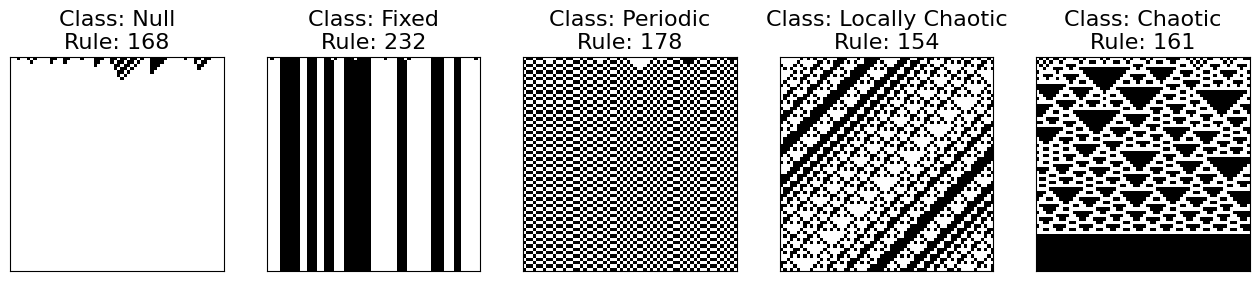

In [3]:
from eca_cnn import figures as F
tv = sets["trainval"]
examples = [tv.diagrams([r * 1024])[0] for r in F.CLASS_EXAMPLE_RULES]
F.lp_classes_examples(examples, F.CLASS_EXAMPLE_RULES);

## 2. The benchmark scan (Sec. 2.1)

The rule table can be read off almost every diagram. The notebook's scan
padded the periodic boundary the wrong way round (`docs/provenance.md` §3.2);
`faithful=True` repeats that, `faithful=False` fixes it.

In [4]:
from eca_cnn.benchmark import scan_set
for faithful in (True, False):
    for which, ds in sets.items():
        res = scan_set(ds, lookup, faithful=faithful)
        print(f"{'faithful ' if faithful else 'corrected'} {which:8s}: {res.n_undetermined:4d} undetermined, "
              f"{len(res.class_ambiguous)} class-ambiguous")

faithful  trainval:  345 undetermined, 4 class-ambiguous


faithful  test    :   43 undetermined, 1 class-ambiguous


corrected trainval:  601 undetermined, 5 class-ambiguous


corrected test    :   83 undetermined, 2 class-ambiguous


## 3. The exact CNN (Sec. 3.1)

Hand-set weights: the eight channels of one convolution detect the eight
neighbourhoods together with a resulting 1, and the output layer turns the
eight bits into a rule. Its answer equals the scanned rule table with missing
entries read as 0.

In [5]:
from eca_cnn.models import exact_cnn, count_parameters
from eca_cnn.benchmark import read_set, table_to_rule
from eca_cnn.batches import DiagramSequence

model = exact_cnn()
test = sets["test"]
pred = model.predict(DiagramSequence(test, np.arange(len(test)), None, 256, batch_size=1024), verbose=0).argmax(1)
scan = table_to_rule(read_set(test), missing_as=0)
count_parameters(model), int((pred != test.rules).sum()), bool(np.array_equal(pred, scan))

(2360, 40, True)

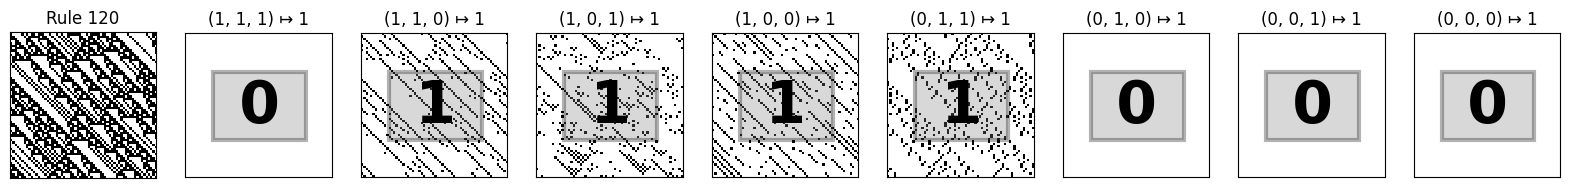

In [6]:
F.convolutional_decomposition(tv.diagrams([120 * 1024])[0], 120);

## 4. The trained networks (Sec. 2.2, 3.2-3.4)

Parameter counts of the default and trimmed CNNs, for each output layer.

In [7]:
from eca_cnn.models import default_cnn, trimmed_cnn
{f"{b.__name__}/{o}": count_parameters(b(o)) for b in (default_cnn, trimmed_cnn)
 for o in ("rules", "classes", "independent")}

{'default_cnn/rules': 6016,
 'default_cnn/classes': 7301,
 'default_cnn/independent': 3160,
 'trimmed_cnn/rules': 1504,
 'trimmed_cnn/classes': 389,
 'trimmed_cnn/independent': 664}

## 5. Augmentation (Sec. 3.3) and the coarse-graining bug (§3.1)

Corrected coarse-graining keeps block means in [0, 1]. The notebook divided
once more by 64², so every "coarse-grained" training diagram was nearly black.

In [8]:
from eca_cnn.augment import coarse_grain
x = tv.diagrams([161 * 1024])[0].astype(np.float32)[None, ..., None]
coarse_grain(x).max(), coarse_grain(x, faithful=True).max()

(1.0, 0.00024414062)

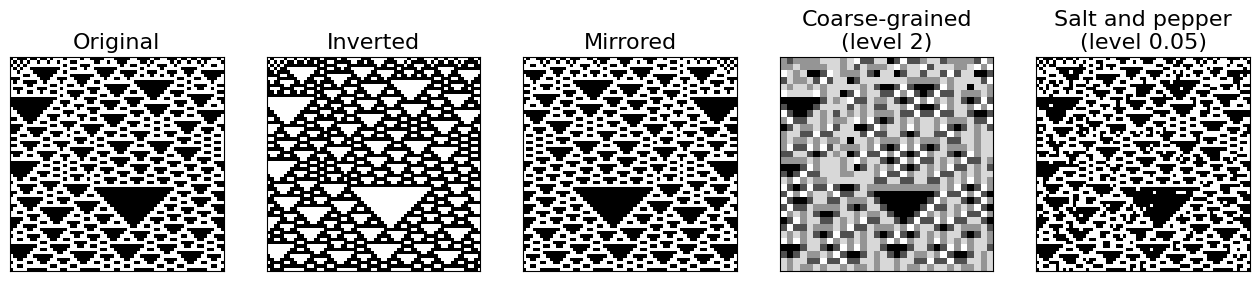

In [9]:
F.augmentation_examples(tv.diagrams([161 * 1024 + 1])[0]);

## 6. Training

Each experiment is a YAML file in `configs/`. A one-epoch smoke run on a few
diagrams per rule checks that a config works:

```
python scripts/train.py --config configs/final_classes.yaml --smoke
python scripts/train.py --config configs/final_classes.yaml                  # the real run
python scripts/train.py --config configs/final_classes.yaml --set mode=faithful
```

`python reproduce.py train` runs every training of the chapter;
`scripts/collect_results.py` puts the results next to the chapter's values.